   Unnamed: 0        holiday    temp  rain_1h  snow_1h  clouds_all  \
0       40255  New Years Day  249.36      0.0      0.0           1   
1       40256            NaN  249.08      0.0      0.0           1   
2       40257            NaN  248.86      0.0      0.0           1   
3       40258            NaN  248.72      0.0      0.0           1   
4       40259            NaN  248.43      0.0      0.0           1   

  weather_main weather_description            date_time  year  month  day  \
0        Clear        sky is clear  2018-01-01 00:00:00  2018      1    1   
1        Clear        sky is clear  2018-01-01 01:00:00  2018      1    1   
2        Clear        sky is clear  2018-01-01 02:00:00  2018      1    1   
3        Clear        sky is clear  2018-01-01 03:00:00  2018      1    1   
4        Clear        sky is clear  2018-01-01 04:00:00  2018      1    1   

    hour  traffic_volume  
0  00:00            1478  
1  01:00            1408  
2  02:00             931  
3  03:00

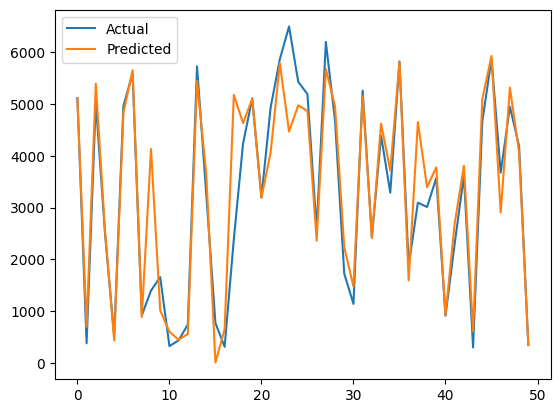

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error
from xgboost import XGBRegressor

# LOAD CSV FILE (your file)
df = pd.read_csv("Metro_Interstate_Traffic_Volume_test.csv")

# Preview data
print(df.head())
print(df.columns)

# Convert date_time column
df['date_time'] = pd.to_datetime(df['date_time'])

# Feature extraction
df['hour'] = df['date_time'].dt.hour
df['day'] = df['date_time'].dt.day
df['month'] = df['date_time'].dt.month

# Drop original column
df = df.drop(['date_time'], axis=1)

# Convert categorical to numeric
df = pd.get_dummies(df, drop_first=True)

# Split data
X = df.drop('traffic_volume', axis=1)
y = df['traffic_volume']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2)

# Model
model = XGBRegressor()
model.fit(X_train, y_train)

# Prediction
y_pred = model.predict(X_test)

# RMSE
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
print("RMSE:", rmse)

# Graph
plt.plot(y_test.values[:50], label="Actual")
plt.plot(y_pred[:50], label="Predicted")
plt.legend()
plt.show()